In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [3]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from threadpoolctl import threadpool_limits

try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

## -- Machine Learning --
# if torch.cuda.is_available():
#     import cupy as cp
#     from cuml.neighbors import KNeighborsClassifier
#     from cuml.linear_model import LogisticRegression
# else:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [4]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 13,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [5]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

# if torch.cuda.is_available():
#     submit = cudf.DataFrame(submit)
#     train = cudf.DataFrame(train)
#     test = cudf.DataFrame(test)
#     orig = cudf.DataFrame(orig)
## ------------------------------------------------------------------------

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [6]:
for c in num_cols:
    train[c] = train[c].fillna(0.0)
    test[c]  = test[c].fillna(0.0)
    orig[c]  = orig[c].fillna(0.0)

print(train.isna().sum())

Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64


In [7]:
train_len = len(train)
test_len  = len(test)

n_unique = train[base_cols].nunique().sort_values()
n_unique

Customer Type                           2
Type of Travel                          2
Gender                                  2
Class                                   3
Baggage handling                        5
Departure/Arrival time convenient       6
Gate location                           6
Inflight wifi service                   6
Leg room service                        6
Checkin service                         6
On-board service                        6
Inflight entertainment                  6
Food and drink                          6
Online boarding                         6
Seat comfort                            6
Ease of Online booking                  6
Cleanliness                             6
Age                                    75
Departure Delay in Minutes            167
Arrival Delay in Minutes              168
Flight Distance                      3474
dtype: int64

In [8]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    weights_ = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return weights_

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    classes_ = np.unique(y_true)
    weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
    class_weights = dict(zip(classes_, weights_))
    return np.array([class_weights[label] for label in y])

print("- Helper Functions Ready -")

- Helper Functions Ready -


# FEATURE ENGINEERING

In [9]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [10]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = orig.groupby(col)[target].mean().reset_index(name=new_col)
                    elif agg_key == 'median':
                        map_df = orig.groupby(col)[target].median().reset_index(name=new_col)
                    elif agg_key == 'count':
                        map_df = orig.groupby(col).size().reset_index(name=new_col)
                    elif agg_key == 'nunique':
                        map_df = orig.groupby(col)[target].nunique().reset_index(name=new_col)
                    elif agg_key == 'std':
                        map_df = orig.groupby(col)[target].std().reset_index(name=new_col)
                    elif agg_key == 'skew':
                        map_df = orig.groupby(col)[target].skew().reset_index(name=new_col)
                    elif agg_key == 'max':
                        map_df = orig.groupby(col)[target].max().reset_index(name=new_col)
                    elif agg_key == 'min':
                        map_df = orig.groupby(col)[target].min().reset_index(name=new_col)
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [11]:
# ## -- Cyclic encoding --
# CYCLICS = []

# for col in ['MonthlyCharges', 'TotalCharges']:
#     for p in [12, 30]:
#         n_s = f'{col}_sin_{p}'
#         n_c = f'{col}_cos_{p}'
#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')

#         test[n_s] = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')

#         orig[n_s] = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')

#         CYCLICS += [n_s, n_c]

# print(f"Cylcic Features created: {len(CYCLICS)}")
# train[CYCLICS].head(3)

In [12]:
FEATURES = [c for c in train.columns if c not in ['id', TARGET]]

# if torch.cuda.is_available:
#     combined = cudf.concat([train, test, orig]).fillna(0)
# else:
combined = pd.concat([train, test, orig])

digit_cols = []
cols_select = ["Flight Distance", "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]
# , "Arrival Delay in Minutes", "Departure Delay in Minutes"

for col in cols_select:
    scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
    for k in range(-4, 4):
        dig_col = f"{col}_digit{k}"
        combined[dig_col] = (scaled // 10**(k + 4) % 10).astype('int32').astype('category')
        # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()

# if torch.cuda.is_available():
#     drop_cols = unique_counts[unique_counts < 2].index.to_arrow().tolist()
# else:
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

# num_cols = list(set(num_cols + digit_cols))
# cat_cols = list(set(cat_cols + digit_cols))

del combined
print(f"Total digit features: {len(digit_cols)}\n")

# train

Total digit features: 12



In [13]:
# poly_feats = []

# for col in ['bmi', 'LapTime_Delta']:
#     for x in [2]:
#         if x == 2:
#             sqr_n = f"_squared_{col}"
#             train[sqr_n] = train[col] ** 2
#             test[sqr_n]  = test[col] ** 2
#             orig[sqr_n]  = orig[col] ** 2
#             poly_feats.append(sqr_n)
#         elif x == 3:
#             cub_n = f"_cubed_{col}"
#             train[cub_n] = train[col] ** 3
#             test[cub_n]  = test[col] ** 3
#             orig[cub_n]  = orig[col] ** 3
#             poly_feats.append(cub_n)


# for col in ['TyreLife', 'RaceProgress', 'Cumulative_Degradation', 'LapTime (s)']:
#     for x in [3]:
#         if x == 2:
#             sqrd_n = f"_squared_{col}"
#             train[sqrd_n] = train[col] ** 2
#             test[sqrd_n]  = test[col] ** 2
#             orig[sqrd_n]  = orig[col] ** 2
#             poly_feats.append(sqrd_n)
#         elif x == 3:
#             cub_n = f"_cubed_{col}"
#             train[cub_n] = train[col] ** 3
#             test[cub_n]  = test[col] ** 3
#             orig[cub_n]  = orig[col] ** 3
#             poly_feats.append(cub_n)
#         else:
#             sqrt_n = f"_sqroot_{col}"
#             train[sqrt_n] = np.sqrt(train[col])
#             test[sqrt_n]  = np.sqrt(test[col])
#             orig[sqrt_n]  = np.sqrt(orig[col])
#             poly_feats.append(sqrt_n)
            
# poly_feats

In [14]:
# def poly_features(df_1, columns, formula=None):
#     df = df_1.copy()
#     poly_feats = []
    
#     print(f'Creating {formula} poly features... ', end='')
#     for col in columns:
#         if formula == 'sqrd':
#             sqrd_n = f"_squared_{col}"
#             df[sqrd_n] = df[col] ** 2
#             poly_feats.append(sqrd_n)
#         elif formula == 'cube':
#             cub_n = f"_cubed_{col}"
#             df[cub_n] = df[col] ** 3
#             poly_feats.append(cub_n)
#         elif formula == 'sqrt':
#             sqrt_n = f"_sqrt_{col}"
#             df[sqrt_n] = np.sqrt(df[col])
#             poly_feats.append(sqrt_n)

#     print(f'{len(poly_feats)} complete!')
            
#     return df, poly_feats

In [15]:
# squared_features = ['sleep_duration', 'heart_rate', 'bmi', 'exercise_duration', 'water_intake']
# train, sqrd_ = poly_features(train, squared_features, formula='sqrd')
# test, sqrd_ = poly_features(test, squared_features, formula='sqrd')

# cubed_features  = ['sleep_duration', 'heart_rate', 'bmi', 'exercise_duration', 'water_intake']
# train, cube_ = poly_features(train, cubed_features, formula='cube')
# test, cube_ = poly_features(test, cubed_features, formula='cube')

# # sqroot_features = ['calorie_expenditure', 'step_count']
# # train, sqrt_ = poly_features(train, sqroot_features, formula='sqrt')
# # test, sqrt_ = poly_features(test, sqroot_features, formula='sqrt')

# poly_feats = sqrd_ + cube_ # + sqrt_ 
# poly_feats

In [16]:
# ## -- Get NaN indicators --
# def appy_nan_indicator(df):
#     df1 = df.copy()
#     cols_with_nan = df1.columns[df1.isna().any()]
#     indicators = df1[cols_with_nan].isna().astype(float).add_prefix('isna_')
#     indi_cols = indicators.columns.tolist()
#     df1 = df1.join(indicators)

#     return df1, indi_cols

# train, INDI_COLS = appy_nan_indicator(train)
# test, _  = appy_nan_indicator(test)
# orig, _  = appy_nan_indicator(orig)
# print(INDI_COLS)

# # ## -- Fill categorical --
# # train[CATS] = train[CATS].fillna('missing')
# # test[CATS]  = test[CATS].fillna('missing')
# # orig[CATS]  = orig[CATS].fillna('missing')

# train

In [17]:
# plt.figure(figsize=(16, 12))
# sns.heatmap(train.select_dtypes(include='number').corr(), annot=True, cbar=False, fmt='.2f', center=0)

# # plt.tight_layout()
# plt.show()

In [18]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

# if torch.cuda.is_available():
#     combined = cudf.concat([train, test, orig])
# else:
combined = pd.concat([train, test, orig])

## ------------------------------------------------------------

# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols.copy() #[c for c in num_cols if train[c].nunique() > 100]
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat] = (pd.factorize(combined[c])[0]).astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(new_cat)
FEATURES = list(set(FEATURES + nums_to_cats))

## ------------------------------------------------------------

## -- Factorize cat_cols --
for c in tqdm(cat_cols, desc="factorize_cats"): # + INTER + new_cats
    combined[c] = (pd.factorize(combined[c])[0]).astype('int32')

# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len] #[FEATURES+[TARGET]]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Label encoding complete!")
print("Total features after operation:", len(FEATURES))

Total features before operation: 33


nums_to_cats:   0%|          | 0/17 [00:00<?, ?it/s]

factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Label encoding complete!
Total features after operation: 50


In [19]:
# ## -- Frequency encoding --
# freq_cols = []
# select_freq = [c for c in base_cols if train[c].nunique() > 2]

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     n = f"_freq_{col}"
#     print(f"⧗ {n}", end="")

#     # Map the training-derived frequencies across all datasets safely
#     # If a category exists in 'test' but wasn't in train/orig, .map() turns it into NaN. 
#     # Using .fillna(1) handles unseeen test categories cleanly.
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n] = test[col].map(freq_map).fillna(0).astype("float32")
#     orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n *** Total frequency features: {len(freq_cols)}")

# train[freq_cols].head()

In [20]:
# ## Create arithmetic features --
# combined = pd.concat([train, test, orig])

# combined['log_total_delays'] = np.log1p(combined['Arrival Delay in Minutes'].fillna(0) + combined['Departure Delay in Minutes'])
# combined['age_distance_ratio'] = combined['Age'] / (combined['Flight Distance']+1)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined

# print(f"Arithmetic features created!")

In [21]:
## -- Create floor features --
floor_cols = []

combined = pd.concat([train, test, orig])

for f in tqdm([100, 250], desc='Floor features (bins)'):
    # print(f, end='-> ')
    for c in ['Flight Distance']:
        f_name = f"{c}_//_{f}"
        print(f" ⧗ {f_name}", end='... ')
        combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
        floor_cols.append(f_name)
        print()

# for f in tqdm([1000], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Flight Distance']:
#         f_name = f"{c}_//_{f}"
#         print(f" ⧗ {f_name}", end='... ')
#         combined[f_name] = (combined[c] // f).astype('float32')
#         floor_cols.append(f_name)
#         print()

for f in tqdm([10], desc='Floor features (bins)'):
    # print(f, end='-> ')
    for c in ['Age']:
        f_name = f"{c}_//_{f}"
        print(f" ⧗ {f_name}", end='... ')
        combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
        floor_cols.append(f_name)
        print()

combined['age10_X_dist250'] = combined['Age_//_10'] * combined['Flight Distance_//_250']

FEATURES = list(set(FEATURES + floor_cols))

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print(f"\n*** Total floor features: {len(floor_cols)}")

print(train[floor_cols].nunique(dropna=False))

Floor features (bins):   0%|          | 0/2 [00:00<?, ?it/s]

 ⧗ Flight Distance_//_100... 
 ⧗ Flight Distance_//_250... 


Floor features (bins):   0%|          | 0/1 [00:00<?, ?it/s]

 ⧗ Age_//_10... 

*** Total floor features: 3
Flight Distance_//_100    44
Flight Distance_//_250    19
Age_//_10                  9
dtype: int64


In [22]:
# INTER = []
# combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_250', 'Age_//_10']

# combo_2_1 = list(itertools.combinations(cat_cols + ['Age'], 2))
# for c1, c2 in tqdm(combo_2_1, desc='Pairwise'):
#     n_col = f"Bi_{c1}_{c2}"
#     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str)).factorize()[0]).astype('int32')
#     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str)).factorize()[0]).astype('int32')
#     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str)).factorize()[0]).astype('int32')
#     INTER.append(n_col)

# combo_3_1 = list(itertools.combinations(cat_cols + ['Flight Distance_//_250', 'Age_//_10'], 3))
# for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise'):
#     n_col = f"Tri_{c1}_{c2}_{c3}"
#     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str) + '_' + train[c3].astype(str)).factorize()[0]).astype('int32')
#     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str) + '_' + test[c3].astype(str)).factorize()[0]).astype('int32')
#     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str) + '_' + orig[c3].astype(str)).factorize()[0]).astype('int32')
#     INTER.append(n_col)

# # combo_2_2 = list(itertools.combinations(['Age_//_10', 'Flight Distance_//_1000'], 2))
# # for c1, c2 in tqdm(combo_2_2, desc='Pairwise'):
# #     n_col = f"Bi_{c1}_{c2}"
# #     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str)).factorize()[0]).astype('int32')
# #     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str)).factorize()[0]).astype('int32')
# #     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str)).factorize()[0]).astype('int32')
# #     INTER.append(n_col)

# # combo_3_list = list(itertools.combinations(digit_cols, 3))
# # for c1, c2, c3 in tqdm(combo_3_list, desc='Triplewise'):
# #     n_col = f"Tri_{c1}_{c2}_{c3}"
# #     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str) + '_' + train[c3].astype(str)).factorize()[0]).astype('int32')
# #     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str) + '_' + test[c3].astype(str)).factorize()[0]).astype('int32')
# #     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str) + '_' + orig[c3].astype(str)).factorize()[0]).astype('int32')
# #     INTER.append(n_col)

# # combo_2_1_2 = list(itertools.product(['Age'], cat_cols))
# # for c1, c2 in tqdm(combo_2_1_2, desc='One-to-Many'):
# #     n_col = f"Bi2_{c1}_{c2}"
# #     train[n_col] = ((train[c1].astype(str) + '_' + train[c2].astype(str)).factorize()[0]).astype('int32')
# #     test[n_col]  = ((test[c1].astype(str) + '_' + test[c2].astype(str)).factorize()[0]).astype('int32')
# #     orig[n_col]  = ((orig[c1].astype(str) + '_' + orig[c2].astype(str)).factorize()[0]).astype('int32')
# #     INTER.append(n_col)

# print(f"Total Interaction Features: {len(INTER)}")
# gc.collect()

In [23]:
INTER = []

combined = pd.concat([train, test, orig], axis=0, ignore_index=True)

combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_250', 'Age_//_10']
comb = [c for c in num_cols if (train[c].nunique() < 10) and (c in base_cols)]

## ------------------------------------------------------------------------
combo_2_1 = list(itertools.combinations(cat_cols + ['Age'], 2)) # 
for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
    n_col = f"Bi_{c1}_X_{c2}"
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

combo_3_1 = list(itertools.combinations(cat_cols + ['Flight Distance_//_250', 'Age_//_10'], 3))
for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
    n_col = f"Tri_{c1}_X_{c2}_X_{c3}"
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)
## ------------------------------------------------------------------------

for n_col in INTER:
    train[n_col] = combined[n_col].iloc[:train_len].values
    test[n_col]  = combined[n_col].iloc[train_len:train_len+test_len].values
    orig[n_col]  = combined[n_col].iloc[train_len+test_len:].values

print(f"Total Interaction Features: {INTER}")

del combined
gc.collect()

Pairwise Sync Encoding:   0%|          | 0/10 [00:00<?, ?it/s]

Triplewise Sync Encoding:   0%|          | 0/20 [00:00<?, ?it/s]

Total Interaction Features: ['Bi_Gender_X_Customer Type', 'Bi_Gender_X_Type of Travel', 'Bi_Gender_X_Class', 'Bi_Gender_X_Age', 'Bi_Customer Type_X_Type of Travel', 'Bi_Customer Type_X_Class', 'Bi_Customer Type_X_Age', 'Bi_Type of Travel_X_Class', 'Bi_Type of Travel_X_Age', 'Bi_Class_X_Age', 'Tri_Gender_X_Customer Type_X_Type of Travel', 'Tri_Gender_X_Customer Type_X_Class', 'Tri_Gender_X_Customer Type_X_Flight Distance_//_250', 'Tri_Gender_X_Customer Type_X_Age_//_10', 'Tri_Gender_X_Type of Travel_X_Class', 'Tri_Gender_X_Type of Travel_X_Flight Distance_//_250', 'Tri_Gender_X_Type of Travel_X_Age_//_10', 'Tri_Gender_X_Class_X_Flight Distance_//_250', 'Tri_Gender_X_Class_X_Age_//_10', 'Tri_Gender_X_Flight Distance_//_250_X_Age_//_10', 'Tri_Customer Type_X_Type of Travel_X_Class', 'Tri_Customer Type_X_Type of Travel_X_Flight Distance_//_250', 'Tri_Customer Type_X_Type of Travel_X_Age_//_10', 'Tri_Customer Type_X_Class_X_Flight Distance_//_250', 'Tri_Customer Type_X_Class_X_Age_//_10', '

57

In [24]:
# ==========================================
# 2. HIGH-IMPACT DOMAIN INTERACTIONS (AUC BOOST) ⚠️
# ==========================================

combined = pd.concat([train, test, orig])

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

# A. Total Delay & Delay Discrepancy
# Tree models easily split on raw values, but explicit sums and differences reduce required tree depth
# combined['Total_Delay'] = combined['Departure Delay in Minutes'].fillna(0) + combined['Arrival Delay in Minutes'].fillna(0)
# combined['Delay_Recovered'] = combined['Departure Delay in Minutes'].fillna(0) - combined['Arrival Delay in Minutes'].fillna(0)
# combined['Is_Delayed'] = (combined['Total_Delay'] > 0).astype('int8').astype('category')

# B. Aggregated Service Experience Scores (Crucial for Passenger Satisfaction datasets)
# Capturing the holistic experience mathematically
combined['Total_Service_Score'] = combined[service_cols].sum(axis=1)
combined['Mean_Service_Score'] = combined[service_cols].mean(axis=1)
combined['Variance_Service_Score'] = combined[service_cols].var(axis=1).astype('float32')

# Segmenting critical service groups
booking_flow = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
comfort_flow = ['Seat comfort', 'Food and drink', 'Leg room service', 'Cleanliness']
combined['Digital_Experience_Score'] = combined[booking_flow].mean(axis=1)
combined['Physical_Comfort_Score'] = combined[comfort_flow].mean(axis=1)

# Count of zero-scores (often represents "Not Applicable" or an extreme pain point)
combined['Count_Zero_Services'] = (combined[service_cols] == 0).sum(axis=1).astype('int8')

# # C. Distance vs. Age Groupings
# combined['Distance_per_Year_of_Age'] = combined['Flight Distance'] / (combined['Age'] + 1)

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Arithmetric features ready")

Arithmetric features ready


In [25]:
_ = [c for c in train.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train.shape}")
train.head()

Train shape (699635, 91)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Flight Distance_digit0,Flight Distance_digit1,Flight Distance_digit2,Flight Distance_digit3,Age_digit0,Age_digit1,Arrival Delay in Minutes_digit0,Arrival Delay in Minutes_digit1,Arrival Delay in Minutes_digit2,Departure Delay in Minutes_digit0,Departure Delay in Minutes_digit1,Departure Delay in Minutes_digit2,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,Flight Distance_//_100,Flight Distance_//_250,Age_//_10,age10_X_dist250,Bi_Gender_X_Customer Type,Bi_Gender_X_Type of Travel,Bi_Gender_X_Class,Bi_Gender_X_Age,Bi_Customer Type_X_Type of Travel,Bi_Customer Type_X_Class,Bi_Customer Type_X_Age,Bi_Type of Travel_X_Class,Bi_Type of Travel_X_Age,Bi_Class_X_Age,Tri_Gender_X_Customer Type_X_Type of Travel,Tri_Gender_X_Customer Type_X_Class,Tri_Gender_X_Customer Type_X_Flight Distance_//_250,Tri_Gender_X_Customer Type_X_Age_//_10,Tri_Gender_X_Type of Travel_X_Class,Tri_Gender_X_Type of Travel_X_Flight Distance_//_250,Tri_Gender_X_Type of Travel_X_Age_//_10,Tri_Gender_X_Class_X_Flight Distance_//_250,Tri_Gender_X_Class_X_Age_//_10,Tri_Gender_X_Flight Distance_//_250_X_Age_//_10,Tri_Customer Type_X_Type of Travel_X_Class,Tri_Customer Type_X_Type of Travel_X_Flight Distance_//_250,Tri_Customer Type_X_Type of Travel_X_Age_//_10,Tri_Customer Type_X_Class_X_Flight Distance_//_250,Tri_Customer Type_X_Class_X_Age_//_10,Tri_Customer Type_X_Flight Distance_//_250_X_Age_//_10,Tri_Type of Travel_X_Class_X_Flight Distance_//_250,Tri_Type of Travel_X_Class_X_Age_//_10,Tri_Type of Travel_X_Flight Distance_//_250_X_Age_//_10,Tri_Class_X_Flight Distance_//_250_X_Age_//_10,Total_Service_Score,Mean_Service_Score,Variance_Service_Score,Digital_Experience_Score,Physical_Comfort_Score,Count_Zero_Services
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,4,9,6,0,6,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6,2,3,6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,37,2.846154,1.807692,4.000000,1.75,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,5,6,0,6,5,0,0,0,0,0,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,6,2,5,10,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,60,4.615385,0.423077,4.666667,4.25,0
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,1,7,3,1,1,3,0,0,0,0,0,0,2,2,2,0,2,1,2,1,2,2,2,2,0,2,1,0,0,13,5,3,15,0,0,0,2,0,0,2,0,2,2,0,0,2,0,0,2,0,2,0,2,0,2,0,2,0,2,2,0,2,2,45,3.461538,0.769231,2.666667,3.00,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,6,1,6,1,0,1,0,0,0,0,0,0,3,3,2,1,3,0,2,1,2,2,2,1,2,1,1,0,0,16,6,1,6,1,2,2,3,0,0,3,0,3,3,2,2,3,2,2,3,2,3,2,3,0,3,2,3,2,3,3,2,3,3,45,3.461538,0.602564,3.000000,3.50,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,1,8,4,0,3,2,0,0,0,5,0,0,4,4,2,0,3,2,1,1,3,1,1,0,1,0,2,1,0,4,1,2,2,2,3,0,4,2,2,4,2,4,4,3,3,4,3,3,4,3,4,3,4,2,4,3,4,3,4,4,3,4,4,54,4.153846,0.807692,3.000000,4.75,0


In [26]:
all_predictions = {}

USE_ORIGINAL   = True
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET].to_numpy(),
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

## -- Handle optional original table aggregations
if USE_ORIGINAL:
    aggs_ = ["mean", "count"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(f"Train shape {X.shape}")
X.head()

(699635, 91) <class 'pandas.core.frame.DataFrame'>


original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

Train shape (699635, 132)


,Physical_Comfort_Score,Tri_Customer Type_X_Class_X_Age_//_10,Inflight wifi service,Flight Distance,Tri_Type of Travel_X_Flight Distance_//_250_X_Age_//_10,Bi_Customer Type_X_Age,Tri_Class_X_Flight Distance_//_250_X_Age_//_10,Tri_Type of Travel_X_Class_X_Flight Distance_//_250,Age_digit0,age10_X_dist250,Checkin service,Tri_Customer Type_X_Type of Travel_X_Class,Mean_Service_Score,Flight Distance_digit0,Leg room service,Arrival Delay in Minutes,Departure Delay in Minutes,Bi_Class_X_Age,Variance_Service_Score,Tri_Gender_X_Type of Travel_X_Flight Distance_//_250,Tri_Customer Type_X_Type of Travel_X_Flight Distance_//_250,Tri_Gender_X_Customer Type_X_Age_//_10,Total_Service_Score,Bi_Type of Travel_X_Age,On-board service,Arrival Delay in Minutes_digit1,Food and drink_cat_,Departure Delay in Minutes_digit0,Checkin service_cat_,Departure/Arrival time convenient,Arrival Delay in Minutes_digit2,Tri_Customer Type_X_Class_X_Flight Distance_//_250,On-board service_cat_,Inflight entertainment_cat_,Bi_Gender_X_Customer Type,Tri_Gender_X_Class_X_Age_//_10,Cleanliness_cat_,Flight Distance_cat_,Ease of Online booking_cat_,Flight Distance_digit1,Inflight wifi service_cat_,Tri_Gender_X_Customer Type_X_Flight Distance_//_250,Age_//_10,Flight Distance_digit2,Online boarding,Bi_Gender_X_Class,Online boarding_cat_,Tri_Type of Travel_X_Class_X_Age_//_10,Gate location,Flight Distance_//_100,...,Age_digit1,Bi_Type of Travel_X_Class,Arrival Delay in Minutes_digit0,Digital_Experience_Score,Flight Distance_digit3,Count_Zero_Services,Seat comfort_cat_,Baggage handling_cat_,oTE_Age_mean,oTE_Age_count,oTE_Flight Distance_mean,oTE_Flight Distance_count,oTE_Inflight wifi service_mean,oTE_Inflight wifi service_count,oTE_Departure/Arrival time convenient_mean,oTE_Departure/Arrival time convenient_count,oTE_Ease of Online booking_mean,oTE_Ease of Online booking_count,oTE_Gate location_mean,oTE_Gate location_count,oTE_Food and drink_mean,oTE_Food and drink_count,oTE_Online boarding_mean,oTE_Online boarding_count,oTE_Seat comfort_mean,oTE_Seat comfort_count,oTE_Inflight entertainment_mean,oTE_Inflight entertainment_count,oTE_On-board service_mean,oTE_On-board service_count,oTE_Leg room service_mean,oTE_Leg room service_count,oTE_Baggage handling_mean,oTE_Baggage handling_count,oTE_Checkin service_mean,oTE_Checkin service_count,oTE_Cleanliness_mean,oTE_Cleanliness_count,oTE_Departure Delay in Minutes_mean,oTE_Departure Delay in Minutes_count,oTE_Arrival Delay in Minutes_mean,oTE_Arrival Delay in Minutes_count,oTE_Gender_mean,oTE_Gender_count,oTE_Customer Type_mean,oTE_Customer Type_count,oTE_Type of Travel_mean,oTE_Type of Travel_count,oTE_Class_mean,oTE_Class_count
0,1.75,0,4,694,0,0,0,0,6,6,3,0,2.846154,4,4,0.0,0,0,1.807692,0,0,0,37,0,3,0,0,0,0,4,0,0,0,0,0,0,0,0,0,9,0,0,3,6,4,0,0,0,3,6,...,3,0,0,4.000000,0,0,0,0,0.354726,2867.0,0.351852,54.0,0.600767,24775.0,0.388614,31880.0,0.531623,24444.0,0.347062,35717.0,0.199551,16051.0,0.623011,38468.0,0.223325,15108.0,0.141946,15675.0,0.318093,28542.0,0.583096,35886.0,0.480636,46761.0,0.450794,35453.0,0.196963,16729.0,0.459390,73356.0,0.473792,73146.0,0.428975,65899.0,0.478115,106100.0,0.101326,40187.0,0.187673,58309.0
1,4.25,1,5,651,1,1,1,1,6,10,4,1,4.615385,1,5,0.0,0,1,0.423077,1,1,1,60,1,5,0,1,0,1,5,0,1,1,1,1,1,1,1,1,5,1,1,5,6,4,1,0,1,5,6,...,5,1,0,4.666667,0,0,1,1,0.572727,2310.0,0.331915,235.0,0.990178,14356.0,0.424709,27998.0,0.734676,17424.0,0.568040,17409.0,0.550882,27957.0,0.623011,38468.0,0.560293,39756.0,0.650615,31544.0,0.646379,29492.0,0.614561,30905.0,0.615916,33878.0,0.460023,36333.0,0.433075,30639.0,0.459390,73356.0,0.473792,73146.0,0.440115,63981.0,0.478115,106100.0,0.583724,89693.0,0.694434,62160.0
2,3.00,0,3,1371,2,2,2,2,1,15,5,0,3.461538,1,3,0.0,0,2,0.769231,2,2,0,45,2,4,0,2,0,2,4,0,2,2,2,0,0,1,2,2,7,2,2,3,3,3,0,1,0,5,13,...,3,0,0,2.666667,1,0,2,0,0.439960,2007.0,0.428571,63.0,0.251825,32185.0,0.388614,31880.0,0.303484,30051.0,0.568040,17409.0,0.397424,27794.0,0.137626,27117.0,0.214078,23328.0,0.273154,2

In [27]:
## -- Reduce data memory --
def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024*1024)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

X = reduce_memory(X)
X_test = reduce_memory(X_test)
# orig  = reduce_memory(orig)

print(f"Data memory reduced!")
print(X.info())

gc.collect()

Reducing memory...:   0%|          | 0/132 [00:00<?, ?it/s]

Size before process: 385.0MB
Size after process : 326.3MB



Reducing memory...:   0%|          | 0/132 [00:00<?, ?it/s]

Size before process: 165.0MB
Size after process : 139.8MB

Data memory reduced!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Columns: 132 entries, Physical_Comfort_Score to oTE_Class_count
dtypes: category(12), float32(47), int32(72), int8(1)
memory usage: 326.3 MB
None


60

In [28]:
# -- Set up parameters --
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True
    USE_GPU = torch.cuda.is_available()

log_params = {
    'C': 0.1,
    "max_iter": 1000,
    "random_state": 42,
    "verbose": 0,
    "n_jobs": -1,
}

all_models = {
    'log': ('LOGITgpu' if CFG.USE_GPU else 'LOGITcpu', log_params),
    # 'loss': ('XGBloss', loss_params),
    # 'grad': ('XGBgrad', loss_params),
}

print(all_models['log'])

# all_models['gbdt']

('LOGITcpu', {'C': 0.1, 'max_iter': 1000, 'random_state': 42, 'verbose': 0, 'n_jobs': -1})


# ML TRAINING

In [29]:
# def Trainer_CV(
#     model_name, params, train_df, test_df, features, target, kfold,
#     one_hot_cats=None, use_te=False, use_orig=False, smooth='auto', with_mean=True,
# ):
#     print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
#     t0 = time()

#     oof_preds  = np.zeros(len(train_df))
#     test_preds = np.zeros(len(test_df))

#     knn_scores   = []
#     fold_scores  = []
#     feat_weights = []
#     # feat_names   = []

#     # Handle optional original table aggregations securely if flags enable them
#     if use_orig and "original_TE" in globals():
#         feats = features.copy()
#         aggs_ = ["mean", "count"] #, "count", "std", "skew"] 
#         X_tr, orig_cols = original_TE(
#             orig, train_df, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
#         )
#         x_test, _ = original_TE(
#             orig, test_df, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
#         )
#         feats.extend(orig_cols)
#         X = X_tr[feats]
#         y = X_tr[target].astype("int32")
#         X_ts = x_test[feats].copy()
#     else:
#         X = train_df[features]
#         y = train_df[target].astype("int32")
#         X_ts = test_df[features].copy()

#     # binary_cols = [c for c in features if X[c].nunique() == 2]

#     for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
#         print(f"\n{"#"*15}")
#         print(f"+++ FOLD {idx}/{kfold.n_splits}")
#         print(f"{"#"*15}")

#         # Split data for the current fold
#         X_train, X_valid = X.iloc[train_idx], X.iloc[val_idx]
#         y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
#         X_test = X_ts.copy()

#         # ## -- OPTION A: Concatenate original data --
#         # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
#         # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)

#         # ## -- OPTION B: TE Merge original data --
#         # X_train, X_valid, X_test, NEW_COLS = orig_TE_data_propagate(
#         #     orig,
#         #     X_train,
#         #     X_valid,
#         #     X_test,
#         #     features=base_cols,
#         #     target=TARGET,
#         #     aggs=['mean'], # mean, median, count, std, nunique, max, min
#         #     fill_nan=True,
#         # )

#         # print(f"Category Mean Encoding: {len(cme_features)} | ", end='')
#         # cme_enc = CategoryMeanTransformer(cat_cols=[c])
#         # X_train[n] = cme_enc.fit_transform(X_train, y_train)
#         # X_valid[n] = cme_enc.transform(X_valid)
#         # X_test[n]  = cme_enc.transform(X_test)

#         ## -- TE Opt1. -> Using CUSTOM --
#         if use_te:
#             te_cols = nums_to_cats + floor_cols + digit_cols #+ INTER # + bin_cols # # #
#             print(f"⚡️ scikit_TE(smooth={smooth}) features({len(te_cols)})")
#             TE = skTE(
#                 target_type='binary',
#                 cv=5,
#                 random_state=42,
#                 smooth=smooth,
#             )
#             te_trn = TE.fit_transform(X_train[te_cols], y_train.to_numpy())
#             te_val = TE.transform(X_valid[te_cols])
#             te_tst = TE.transform(X_test[te_cols])

#             te_names = [f"TE_{c}" for c in te_cols]
#             X_train[te_names] = te_trn
#             X_valid[te_names] = te_val
#             X_test[te_names]  = te_tst
    
#             # Drop original features
#             X_train = X_train.drop(te_cols, axis=1)
#             X_valid = X_valid.drop(te_cols, axis=1)
#             X_test  = X_test.drop(te_cols, axis=1)
#         else:
#             te_cols = []

#         te_features = [c for c in X_train.columns if c.startswith(('TE_', 'oTE_'))]
#         # binary_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
#         # no_scale_cols = one_hot_cats+te_features+binary_cols+['RaceProgress']#+freq_cols

#         # scale_cols = [c for c in X_train.columns if c not in no_scale_cols]

#         ## -- Handle missing numeric data --
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
#         print(f"train={X_train.shape}, valid={X_valid.shape}")

#         ## -- Define encoders --
#         scaler_enc  = StandardScaler() if with_mean else StandardScaler(with_mean=False)
#         ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
#         num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=42)
#         cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
#         ## ------------------------------------------------------------------------
#         # num_cols = [c for c in X_train.columns if c not in one_hot_cats]
#         ohe_cols  = [c for c in X_train.columns if c.startswith('ohe_')]
#         only_nums = [c for c in X_train.columns if c not in list(set(one_hot_cats))]

#         num_proc = make_pipeline(scaler_enc)
#         cat_proc = make_pipeline(ohe_enc)

#         preprocessor = make_column_transformer(
#             (num_proc, only_nums),
#             (cat_proc, one_hot_cats),
#             remainder='passthrough',
#             n_jobs=-1,
#         )

#         if idx == 1:
#             display(X_train.head(3))

#         ## ------------------------------------------------------------------------
#         if "KNN" in model_name:
#             ## -- Create pipeline --
#             model = make_pipeline(preprocessor, KNeighborsClassifier(**params), verbose=True)
#         elif 'MLP' in model_name:
#             model = make_pipeline(preprocessor, MLPClassifier(**params), verbose=True)
#         else:
#             model = make_pipeline(preprocessor, LogisticRegression(**params), verbose=True)

#         ## -- Train Model --
#         # with threadpool_limits(limits=1, user_api='blas'):
        
#         model.fit(X_train, y_train)

#         weights_out = model[-1].coef_[0]
#         names_out = model.named_steps['columntransformer'].get_feature_names_out()
#         print(f"⚡️ Total expanded features: {len(names_out)}")

#         imp_df = pd.DataFrame({"feature": names_out, f"fold{idx}_coef": weights_out})
#         feat_weights.append(imp_df)

#         # .sort_values(by="importance_score", ascending=False).reset_index(drop=True)
#         # print(f"feature importances table")
#         # display(imp_df.head())

#         ## -- Predict on validation and test sets --
#         oof_preds[val_idx] = model.predict_proba(X_valid)[:, 1]
#         test_preds += model.predict_proba(X_test)[:, 1] / kfold.n_splits

#         ## -- Fold score --
#         fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
#         fold_scores.append(fold_score)

#         print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")

#         shape = X_train.shape

#         ## -- Clean up memory --
#         del X_train, y_train, X_test, imp_df
#         gc.collect()

#     # ## -- Average the test predictions
#     # test_preds /= kfold.n_splits

#     ## -- CV results --
#     print(f"\n{'='*50}")
#     print(f"{kfold.n_splits}-FOLD CV: {model_name} | shape:{shape} -> {len(names_out)}")
#     print(f"{'='*50}")
#     for i, s in enumerate(fold_scores, 1):
#         print(f" • Fold {i} AUC: {s:.6f}")

#     ## -- Final out-of-fold score --
#     oof_score = np.round(roc_auc_score(y, oof_preds), 6)
#     avg_score = np.round(np.mean(fold_scores), 6)
#     std_score = np.round(np.std(fold_scores), 6)

#     print(f"{'-'*50}")
#     print(f"OOF score: {oof_score}")
#     print(f"AVG score: {avg_score} ± {std_score}")
#     print(f"{'-'*50}")

#     total_time = np.round((time()-t0)/60, 2)
#     print(f"Duration: {total_time} mins")

#     return {
#         'oof_preds': oof_preds,
#         'test_preds':test_preds,
#         'score': avg_score,
#         'model': model,
#         'val_data': [X_valid, y_valid],
#         'weights': feat_weights,
#         'total_time': total_time,
#     }

# print("⚙️ Training function ready ⚙️")

In [30]:
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

ID = 'log'
model_name = all_models[ID][0]
print(f"\n🚀 Training {model_name} with {FOLDS } Folds", end=" | ")

oof_preds  = np.zeros(len(train_X))
test_preds = np.zeros(len(X_test))

one_hot_cats = [c for c in base_cols if train_X[c].nunique() < 50] + INTER # digit_cols

fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_tr = y.iloc[tr_idx].values
    y_val = y.iloc[val_idx].values
    X_tst = X_test.copy()

    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + floor_cols + digit_cols # + INTER 
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols].to_numpy(), y_tr)
        va_enc = TE.transform(X_val[te_cols].to_numpy())
        ts_enc = TE.transform(X_tst[te_cols].to_numpy())

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ------------------------------------------------------------------------------
    ## -- Define encoders --
    scaler_enc  = StandardScaler()
    ohe_enc     = OneHotEncoder(handle_unknown="ignore", sparse_output=True, drop='if_binary')
    num_imputer = IterativeImputer(max_iter=50, tol=1e-3, add_indicator=True, random_state=42)
    cat_imputer = SimpleImputer(strategy="most_frequent", add_indicator=True)
    ## ------------------------------------------------------------------------
    te_features = [c for c in X_tr.columns if c.startswith(('TE_', 'oTE_'))]
    only_nums = [c for c in X_tr.columns if c not in list(set(one_hot_cats))]

    num_process = make_pipeline(scaler_enc)
    cat_process = make_pipeline(ohe_enc)

    preprocessor = make_column_transformer(
        (cat_process, one_hot_cats),
        (num_process, only_nums),
        remainder='passthrough',
        verbose_feature_names_out=False,
        n_jobs=None if CFG.USE_GPU else -1,
    )
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")
    print("#"*16)
    print(f"### Fold {fold}/{FOLDS} ...")
    print("#"*16)

    seeder = 42 #+ (fold-1)

    params = all_models[ID][1].copy()
    params['random_state'] = seeder
    params['n_jobs'] = None if CFG.USE_GPU else -1

    model = make_pipeline(preprocessor, LogisticRegression(**params), verbose=True)
    model.fit(X_tr, y_tr)

    weights_out = model[-1].coef_[0]
    names_out = model.named_steps['columntransformer'].get_feature_names_out()
    print(f"⚡️ Total expanded features: {len(names_out)}")

    imp_df = pd.DataFrame({"feature": names_out, f"fold{fold}_coef": weights_out})
    feat_importances.append(imp_df)

    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    fold_test_preds = model.predict_proba(X_tst)[:, 1]
    test_preds += fold_test_preds / FOLDS

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    best_iterations.append(model[-1].n_iter_)
    print(f"seed={seeder}", end=" | ")
    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.6f}{Style.RESET_ALL}\n")
    torch.cuda.empty_cache()

model_name = model_name + f"({len(names_out)})"

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape} -> {len(names_out)}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ epoch {t}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)
print(f"{((time()-t0)/60):.2f} mins\n")

del X_tr, y_tr


🚀 Training LOGITcpu with 5 Folds | ⚡️ scikit_TE (smooth=auto) | features (32)
train=(559708, 132), valid=(139927, 132)

################
### Fold 1/5 ...
################
[Pipeline] . (step 1 of 2) Processing columntransformer, total=  10.8s
[Pipeline]  (step 2 of 2) Processing logisticregression, total=  37.9s
⚡️ Total expanded features: 2850


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [23, 32, 34, 36, 37, 42, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [25, 26, 29, 34, 36, 38, 41, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


seed=42 | Fold 1 | AUC: 0.951884

⚡️ scikit_TE (smooth=auto) | features (32)
################
### Fold 2/5 ...
################
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   9.3s
[Pipeline]  (step 2 of 2) Processing logisticregression, total=  34.7s
⚡️ Total expanded features: 2831


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [23, 26, 32, 34, 36, 38, 40, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [25, 26, 29, 34, 36, 38, 41, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


seed=42 | Fold 2 | AUC: 0.950671

⚡️ scikit_TE (smooth=auto) | features (32)
################
### Fold 3/5 ...
################
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   9.1s
[Pipeline]  (step 2 of 2) Processing logisticregression, total=  38.2s
⚡️ Total expanded features: 2849


...

seed=42 | Fold 3 | AUC: 0.951940

⚡️ scikit_TE (smooth=auto) | features (32)
################
### Fold 4/5 ...
################
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   9.0s
[Pipeline]  (step 2 of 2) Processing logisticregression, total=  29.8s
⚡️ Total expanded features: 2848


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [32, 34, 36, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [25, 26, 29, 34, 36, 38, 41, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


seed=42 | Fold 4 | AUC: 0.951603

⚡️ scikit_TE (smooth=auto) | features (32)
################
### Fold 5/5 ...
################
[Pipeline] . (step 1 of 2) Processing columntransformer, total=   9.1s
[Pipeline]  (step 2 of 2) Processing logisticregression, total=  36.2s
⚡️ Total expanded features: 2846


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [20, 23, 26, 29, 36, 40, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [25, 26, 29, 34, 36, 38, 40, 41, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


seed=42 | Fold 5 | AUC: 0.951331


5-FOLD CV: LOGITcpu(2846) | (559708, 132) -> 2846
 • Fold 1 AUC: 0.951884 @ epoch [137]
 • Fold 2 AUC: 0.950671 @ epoch [124]
 • Fold 3 AUC: 0.951940 @ epoch [143]
 • Fold 4 AUC: 0.951603 @ epoch [110]
 • Fold 5 AUC: 0.951331 @ epoch [136]
--------------------------------------------------
OOF score: 0.951483
AVG score: 0.951486 ± 0.000462
--------------------------------------------------
5.09 mins



In [31]:
# ==================================================
# 5-FOLD CV: LOGITcpu(2846) | (559708, 132) -> 2846
# ==================================================
#  • Fold 1 AUC: 0.951884 @ epoch [137]
#  • Fold 2 AUC: 0.950671 @ epoch [124]
#  • Fold 3 AUC: 0.951936 @ epoch [146]
#  • Fold 4 AUC: 0.951603 @ epoch [110]
#  • Fold 5 AUC: 0.951335 @ epoch [156]
# --------------------------------------------------
# OOF score: 0.951483
# AVG score: 0.951486 ± 0.000461
# --------------------------------------------------
# 5.67 mins

In [32]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print("" + "-"*20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*20)

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())
print(f"{((time()-t0)/60):.2f} mins\n")

--------------------
LOGITcpu(2846)_951486
--------------------
           score
fold_1  0.951884
fold_2  0.950671
fold_3  0.951940
fold_4  0.951603
fold_5  0.951331
9.93 mins



In [35]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.137574
1,699636,0.880806
2,699637,0.736443
3,699638,0.031822
4,699639,0.005909
...,...,...
299839,999474,0.135212
299840,999475,0.015129
299841,999476,0.081643
299842,999477,0.035670


In [36]:
# !rm -r /kaggle/working/

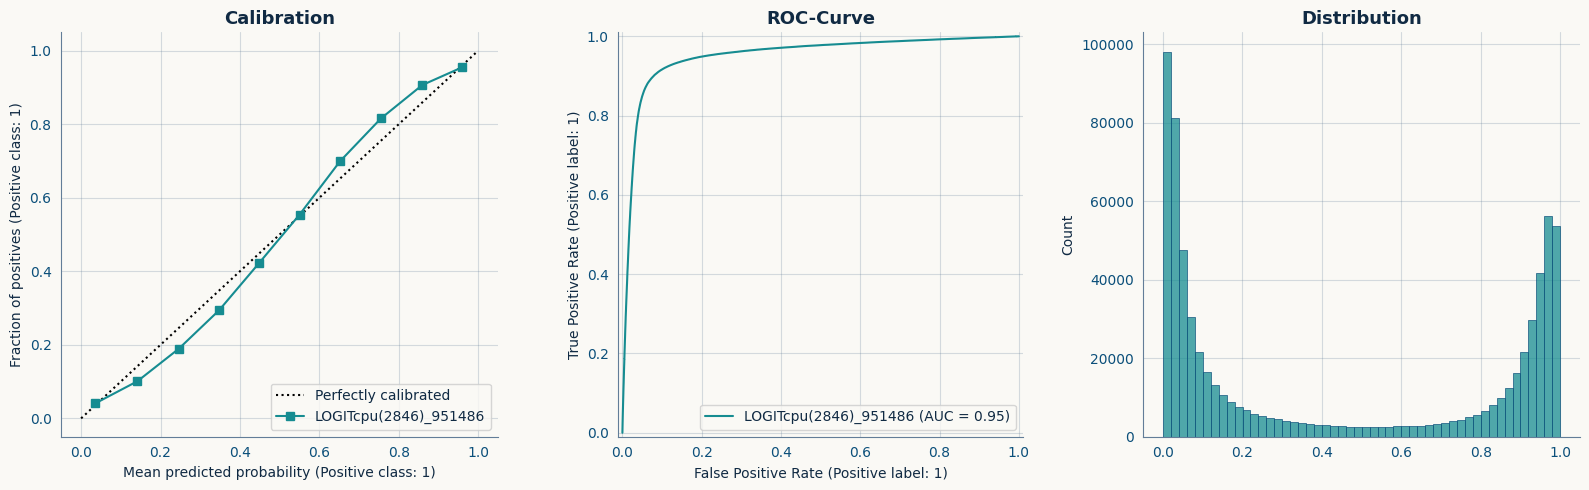

In [37]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(16, 5))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [38]:
np1 = [2.5, 60.4, 56.9, 305.67]
np2 = [61.3, 5.7, 2.5]
padded_pairs = list(itertools.zip_longest(np1, np2, fillvalue=0))
np.mean(padded_pairs, axis=1)

array([ 31.9  ,  33.05 ,  29.7  , 152.835])

,feature,fold1_coef,fold2_coef,fold3_coef,fold4_coef,fold5_coef,avg_score
0,Inflight wifi service_0,0.206135,0.214459,0.171962,0.209745,0.206522,0.201764
1,Inflight wifi service_1,-0.380382,-0.386739,-0.355856,-0.399288,-0.371909,-0.378835
2,Inflight wifi service_2,0.159992,0.148588,0.140977,0.161128,0.144833,0.151104
3,Inflight wifi service_3,0.073384,0.082128,0.061081,0.083175,0.077493,0.075452
4,Inflight wifi service_4,-0.273193,-0.264882,-0.255233,-0.278644,-0.265299,-0.267450


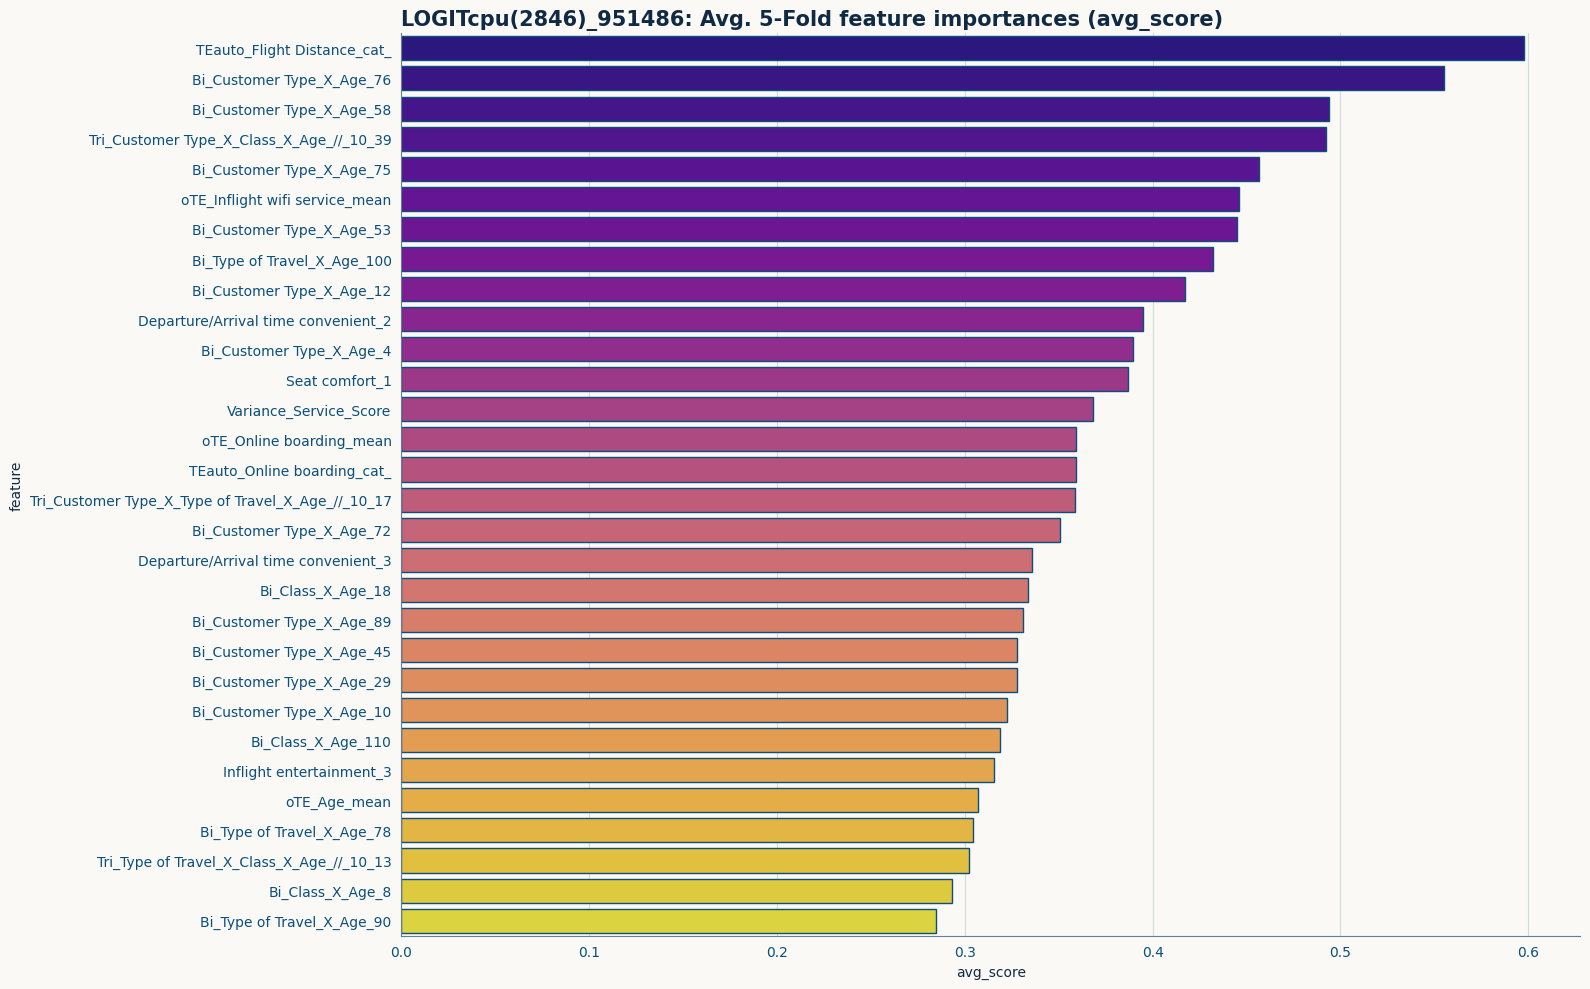

In [39]:
top_n  = 30

df = feat_importances[0]
df = df.merge(feat_importances[1], how='left', on='feature')
df = df.merge(feat_importances[2], how='left', on='feature')
df = df.merge(feat_importances[3], how='left', on='feature')
df = df.merge(feat_importances[4], how='left', on='feature')
df['avg_score'] = df.iloc[:, -5:].mean(axis=1)
# df['avg_X_std'] = df['avg_score'] * df['avg_score'].std()
display(df.head())

# - Plot feature coef weights --
x = 'avg_X_std' if 'avg_X_std' in df.columns else 'avg_score'
df = df.sort_values(by=x, ascending=False)

plt.figure(figsize=(16, 10))
sns.barplot(data=df.head(top_n), x=x, y="feature", palette='plasma')
plt.title(f"{n}: Avg. {FOLDS}-Fold feature importances ({x})", size=15, weight="semibold", loc='left')

plt.tight_layout()
plt.show()
    # break

In [40]:
try:
    import shap
except:
    !uv pip install shap
    import shap

print(f"Shap version: {shap.__version__}")

Shap version: 0.52.0


In [41]:
X_val.head()

,Physical_Comfort_Score,Tri_Customer Type_X_Class_X_Age_//_10,Inflight wifi service,Flight Distance,Tri_Type of Travel_X_Flight Distance_//_250_X_Age_//_10,Bi_Customer Type_X_Age,Tri_Class_X_Flight Distance_//_250_X_Age_//_10,Tri_Type of Travel_X_Class_X_Flight Distance_//_250,age10_X_dist250,Checkin service,Tri_Customer Type_X_Type of Travel_X_Class,Mean_Service_Score,Leg room service,Arrival Delay in Minutes,Departure Delay in Minutes,Bi_Class_X_Age,Variance_Service_Score,Tri_Gender_X_Type of Travel_X_Flight Distance_//_250,Tri_Customer Type_X_Type of Travel_X_Flight Distance_//_250,Tri_Gender_X_Customer Type_X_Age_//_10,Total_Service_Score,Bi_Type of Travel_X_Age,On-board service,Departure/Arrival time convenient,Tri_Customer Type_X_Class_X_Flight Distance_//_250,Bi_Gender_X_Customer Type,Tri_Gender_X_Class_X_Age_//_10,Tri_Gender_X_Customer Type_X_Flight Distance_//_250,Online boarding,Bi_Gender_X_Class,Tri_Type of Travel_X_Class_X_Age_//_10,Gate location,Type of Travel,Tri_Gender_X_Customer Type_X_Type of Travel,Gender,Bi_Gender_X_Age,Bi_Gender_X_Type of Travel,Seat comfort,Ease of Online booking,Class,Tri_Gender_X_Type of Travel_X_Age_//_10,Age,Bi_Customer Type_X_Type of Travel,Tri_Gender_X_Class_X_Flight Distance_//_250,Cleanliness,Tri_Gender_X_Type of Travel_X_Class,Baggage handling,Bi_Customer Type_X_Class,Tri_Gender_X_Customer Type_X_Class,Inflight entertainment,...,oTE_Baggage handling_mean,oTE_Baggage handling_count,oTE_Checkin service_mean,oTE_Checkin service_count,oTE_Cleanliness_mean,oTE_Cleanliness_count,oTE_Departure Delay in Minutes_mean,oTE_Departure Delay in Minutes_count,oTE_Arrival Delay in Minutes_mean,oTE_Arrival Delay in Minutes_count,oTE_Gender_mean,oTE_Gender_count,oTE_Customer Type_mean,oTE_Customer Type_count,oTE_Type of Travel_mean,oTE_Type of Travel_count,oTE_Class_mean,oTE_Class_count,TEauto_Age_cat_,TEauto_Flight Distance_cat_,TEauto_Inflight wifi service_cat_,TEauto_Departure/Arrival time convenient_cat_,TEauto_Ease of Online booking_cat_,TEauto_Gate location_cat_,TEauto_Food and drink_cat_,TEauto_Online boarding_cat_,TEauto_Seat comfort_cat_,TEauto_Inflight entertainment_cat_,TEauto_On-board service_cat_,TEauto_Leg room service_cat_,TEauto_Baggage handling_cat_,TEauto_Checkin service_cat_,TEauto_Cleanliness_cat_,TEauto_Departure Delay in Minutes_cat_,TEauto_Arrival Delay in Minutes_cat_,TEauto_Flight Distance_//_100,TEauto_Flight Distance_//_250,TEauto_Age_//_10,TEauto_Flight Distance_digit2,TEauto_Arrival Delay in Minutes_digit1,TEauto_Departure Delay in Minutes_digit0,TEauto_Arrival Delay in Minutes_digit2,TEauto_Departure Delay in Minutes_digit1,TEauto_Age_digit0,TEauto_Departure Delay in Minutes_digit2,TEauto_Age_digit1,TEauto_Arrival Delay in Minutes_digit0,TEauto_Flight Distance_digit1,TEauto_Flight Distance_digit3,TEauto_Flight Distance_digit0
4,4.75,3,3,481,4,4,4,4,2,3,2,4.153846,4,0.0,5,4,0.807692,4,4,3,54,4,5,4,4,2,3,4,3,0,3,4,1,3,0,4,3,5,3,0,3,23,2,4,5,3,5,2,3,5,...,0.615916,33878.0,0.450794,35453.0,0.612472,28416.0,0.457397,2136.0,0.473792,73146.0,0.428975,65899.0,0.239697,23780.0,0.583724,89693.0,0.187673,58309.0,0.348369,0.317892,0.276123,0.401198,0.320739,0.409473,0.566400,0.128066,0.671479,0.672059,0.657458,0.593583,0.609700,0.460017,0.630832,0.431919,0.452056,0.290723,0.310220,0.314562,0.493838,0.449564,0.389119,0.443617,0.447584,0.472516,0.443615,0.314562,0.451196,0.446985,0.298247,0.408631
5,1.50,4,4,584,5,5,5,1,6,4,3,2.923077,3,0.0,0,5,1.910256,5,5,4,38,5,3,4,5,2,4,5,4,3,4,4,1,3,0,5,3,1,4,1,4,34,2,5,1,4,4,3,4,1,...,0.480636,46761.0,0.460023,36333.0,0.196963,16729.0,0.459390,73356.0,0.473792,73146.0,0.428975,65899.0,0.239697,23780.0,0.583724,89693.0,0.694434,62160.0,0.340475,0.297850,0.621806,0.401198,0.555103,0.409473,0.170985,0.641624,0.173608,0.126711,0.290575,0.266488,0.482734,0.470365,0.154515,0.447993,0.452056,0.306120,0.294602,0.391042,0.412642,0.449564,0.447437,0.443617,0.447584,0.437460,0.443615,0.391042,0.451196,0.446985,0.298247,0.449472
6,3.50,5,5,1763,6,0,6,5,21

In [43]:
feat_names = model.named_steps['columntransformer'].get_feature_names_out()
print(f"Model pipeline features: {len(feat_names)}")

x_val = model[:-1].transform(X_val).toarray() # convert sparze to numpy

# Randomly select 100 rows without replacement
rng = np.random.default_rng(seed=42)
indices = rng.choice(x_val.shape[0], size=100, replace=False)
val_x = x_val[indices]
val_y = y_val[indices]

## -- Shap Explainer --
def f(x):
    return model[-1].predict_proba(x)[:, 1]

Model pipeline features: 2846


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [20, 23, 26, 29, 36, 40, 42, 43, 45, 46] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [44]:
val_y

array([1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0], dtype=int32)

PermutationExplainer explainer: 101it [18:30, 11.10s/it]                         


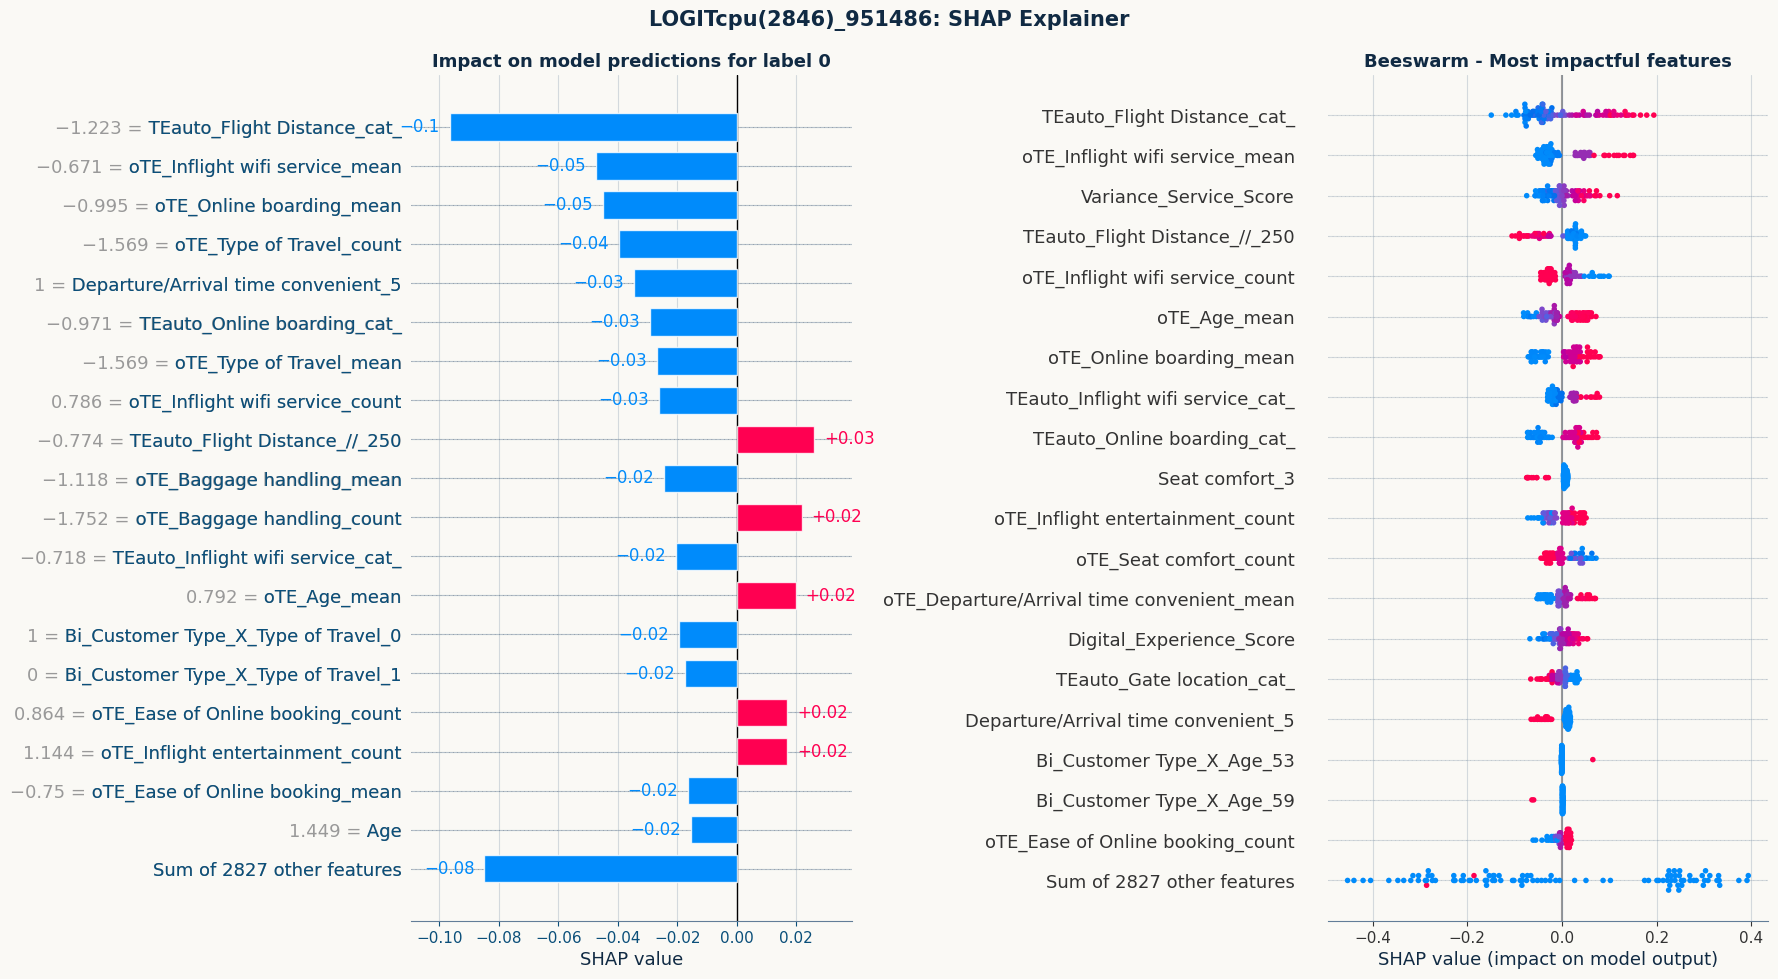

In [45]:
_id = 2
MAX = 20

explainer   = shap.Explainer(f, val_x, feature_names=feat_names, seed=42)
explanation = explainer(val_x, max_evals=max(500, 2*val_x.shape[1]+1))

## -- Bar plot --
plt.subplot(121)
shap.plots.bar(explanation[_id], max_display=MAX, show=False)
plt.title(f"Impact on model predictions for label {val_y[_id]}")

## -- Beeswarm plot --
plt.subplot(122)
shap.plots.beeswarm(
    explanation,
    order=explanation.abs.max(0),
    plot_size=(18, 10),
    max_display=MAX,
    color_bar=False,
    show=False,
)
plt.title("Beeswarm - Most impactful features")

plt.suptitle(f"{n}: SHAP Explainer", size=15, weight="semibold")
plt.tight_layout(pad=1.5)
plt.show()

print()